# 18. Klasifikasi Audio Berisik vs Non-Berisik (Model 3.0)

**Tujuan:** Menguji apakah penambahan 7 fitur rasio dinamis dan arsitektur **Soft-Voting Ensemble** (Robust SVM + LightGBM + ExtraTrees) dapat meningkatkan akurasi dibanding Model 2.0 (holdout 92.68%).

**Dataset:** `berisik` (101 file) dan `non-berisik` (100 file), format MP3, durasi ±30 detik per file.

**Protokol evaluasi:** split 80/20 yang sama dengan Model 2.0 (`random_state=42`). Data uji tidak dipakai untuk memilih threshold atau hyperparameter. Perbandingan cross-validation memakai fold yang sama untuk kedua model.

**Ringkasan hasil:** lihat bagian 18.7 dan 18.10. Pada eksperimen ini Model 3.0 **tidak** memberikan peningkatan akurasi holdout dibanding Model 2.0.


## 18.1 Setup & Pustaka

In [12]:
import warnings
warnings.filterwarnings('ignore')

import hashlib
import math
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import librosa
from scipy.signal import resample_poly

from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.svm import SVC

import lightgbm as lgb

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (11, 4.5)
RANDOM_STATE = 42

BASE_DIR = Path('..') if (Path('..') / 'berisik').exists() else Path('.')
KELAS = ['berisik', 'non-berisik']
PALETTE = {'berisik': '#e74c3c', 'non-berisik': '#2ecc71'}
SR = 22050

print("Library berhasil dimuat.")


Library berhasil dimuat.


## 18.2 Inventaris Data & Verifikasi Dataset

In [13]:
files_berisik = sorted(list((BASE_DIR / 'berisik').glob('*.mp3')) + list((BASE_DIR / 'berisik').glob('*.MP3')))
files_non = sorted(list((BASE_DIR / 'non-berisik').glob('*.mp3')) + list((BASE_DIR / 'non-berisik').glob('*.MP3')))

print(f"File berisik     : {len(files_berisik)}")
print(f"File non-berisik : {len(files_non)}")
print(f"Total file audio : {len(files_berisik) + len(files_non)}")


File berisik     : 202
File non-berisik : 200
Total file audio : 402


## 18.3 Ekstraksi Fitur Audio Generasi 3 (107 Fitur)

Mengekstrak 100 fitur dasar (RMS dB, noise floor quiet frames, 20 MFCC, noise floor mel, spectral contrast) ditambah **7 fitur dinamis volume-invariant** untuk membedakan percakapan berjarak jauh dari desis ruangan.

In [14]:
def load_audio(path, target_sr=22050):
    """Membaca file audio ke mono float32 dengan resample cepat."""
    data, sr = sf.read(str(path), dtype='float32', always_2d=True)
    mono = data.mean(axis=1)
    if sr != target_sr:
        div = math.gcd(sr, target_sr)
        mono = resample_poly(mono, target_sr // div, sr // div).astype(np.float32)
    return mono


def ekstrak_fitur_v3(y, sr=22050):
    """Ekstraksi 107 fitur spektral, energi, dan rasio dinamis."""
    f = {}
    S = np.abs(librosa.stft(y, n_fft=2048, hop_length=512))

    # 1. Energi RMS dB
    rms = librosa.feature.rms(S=S)[0]
    rms_db = librosa.amplitude_to_db(rms + 1e-10, ref=1.0)
    pct = np.percentile(rms_db, [5, 10, 25, 50, 75, 90, 95])
    for q, v in zip([5, 10, 25, 50, 75, 90, 95], pct):
        f[f'rmsdb_p{q}'] = float(v)
    f['dyn_range'] = float(pct[-1] - pct[0])
    f['snr_est'] = float(pct[-1] - pct[1])
    f['rmsdb_std'] = float(rms_db.std())

    # 2. Frame tersunyi & spektral dasar
    quiet = rms_db <= np.percentile(rms_db, 20)
    flat = librosa.feature.spectral_flatness(S=S)[0]
    cent = librosa.feature.spectral_centroid(S=S, sr=sr)[0]
    zcr = librosa.feature.zero_crossing_rate(y, hop_length=512)[0][: S.shape[1]]

    spectral_features = {
        'flat': flat, 'cent': cent, 'zcr': zcr,
        'bw': librosa.feature.spectral_bandwidth(S=S, sr=sr)[0],
        'roll': librosa.feature.spectral_rolloff(S=S, sr=sr)[0],
    }
    for nama, v in spectral_features.items():
        v = v[: len(quiet)]
        f[f'{nama}_mean'] = float(v.mean())
        f[f'{nama}_std'] = float(v.std())
        quiet_part = v[quiet[: len(v)]]
        f[f'{nama}_quiet'] = float(quiet_part.mean() if len(quiet_part) > 0 else v.mean())

    # 3. 20 Koefisien MFCC
    mel = librosa.power_to_db(librosa.feature.melspectrogram(S=S**2, sr=sr, n_mels=40))
    mfcc = librosa.feature.mfcc(S=mel, n_mfcc=20)
    for i in range(20):
        f[f'mfcc{i + 1}_mean'] = float(mfcc[i].mean())
        f[f'mfcc{i + 1}_std'] = float(mfcc[i].std())
        mfcc_quiet = mfcc[i][quiet]
        f[f'mfcc{i + 1}_quiet'] = float(mfcc_quiet.mean() if len(mfcc_quiet) > 0 else mfcc[i].mean())

    # 4. Noise floor 8-band mel
    mq = mel[:, quiet].mean(axis=1) if np.any(quiet) else mel.mean(axis=1)
    for i, band in enumerate(np.array_split(mq, 8)):
        f[f'noise_band{i + 1}'] = float(band.mean())

    # 5. Spectral contrast (7 band)
    con = librosa.feature.spectral_contrast(S=S, sr=sr)
    for i in range(con.shape[0]):
        f[f'contrast{i + 1}'] = float(con[i].mean())

    # 6. Fitur Dinamis Model 3.0 (Volume-Invariant)
    f['dyn_ratio'] = float(f['dyn_range'] / (f['rmsdb_std'] + 1e-5))
    f['snr_dyn_ratio'] = float(f['snr_est'] / (f['dyn_range'] + 1e-5))
    f['hf_energy_ratio'] = float(f['contrast5'] + f['contrast6'] + f['contrast7'] - (f['contrast1'] + f['contrast2']))
    f['cent_bw_ratio'] = float(f['cent_mean'] / (f['bw_mean'] + 1e-5))
    f['roll_cent_ratio'] = float(f['roll_mean'] / (f['cent_mean'] + 1e-5))
    f['flat_cent_prod'] = float(f['flat_mean'] * f['cent_mean'])
    f['snr_ratio_p95_p5'] = float(f['rmsdb_p95'] / (f['rmsdb_p5'] - 1e-5))

    return f


In [15]:
# Membaca dataset dasar dan menghitung 7 fitur dinamis baru
csv_src = Path('../model2.0/output_fitur_berisik.csv')
df_base = pd.read_csv(csv_src)

feature_cols_base = [c for c in df_base.columns if c not in ['file', 'label']]
X_base = df_base[feature_cols_base].copy()

# Hitung 7 fitur baru
X_base['dyn_ratio'] = X_base['dyn_range'] / (X_base['rmsdb_std'] + 1e-5)
X_base['snr_dyn_ratio'] = X_base['snr_est'] / (X_base['dyn_range'] + 1e-5)
X_base['hf_energy_ratio'] = X_base['contrast5'] + X_base['contrast6'] + X_base['contrast7'] - (X_base['contrast1'] + X_base['contrast2'])
X_base['cent_bw_ratio'] = X_base['cent_mean'] / (X_base['bw_mean'] + 1e-5)
X_base['roll_cent_ratio'] = X_base['roll_mean'] / (X_base['cent_mean'] + 1e-5)
X_base['flat_cent_prod'] = X_base['flat_mean'] * X_base['cent_mean']
X_base['snr_ratio_p95_p5'] = X_base['rmsdb_p95'] / (X_base['rmsdb_p5'] - 1e-5)

df_fitur = pd.concat([df_base[['file', 'label']], X_base], axis=1)
df_fitur.to_csv('output_fitur_berisik.csv', index=False)
print(f"Dataset fitur Model 3.0: {df_fitur.shape[0]} baris, {df_fitur.shape[1] - 2} fitur numerik")
df_fitur.head(3)


Dataset fitur Model 3.0: 201 baris, 107 fitur numerik


,file,label,rmsdb_p5,rmsdb_p10,rmsdb_p25,rmsdb_p50,rmsdb_p75,rmsdb_p90,rmsdb_p95,dyn_range,...,contrast5,contrast6,contrast7,dyn_ratio,snr_dyn_ratio,hf_energy_ratio,cent_bw_ratio,roll_cent_ratio,flat_cent_prod,snr_ratio_p95_p5
0,24-003 berisik (1).mp3,berisik,-42.240409,-40.725087,-36.848579,-33.108852,-29.683816,-26.803222,-25.322854,16.917555,...,19.628800,21.215021,64.402323,3.267388,0.910428,66.955290,0.885823,2.206517,4.555932,0.599493
1,24-003 berisik (2).mp3,berisik,-50.211131,-43.896641,-34.648829,-27.809125,-23.385540,-20.620440,-19.390105,30.821026,...,20.905576,27.293818,54.476193,3.100677,0.795124,64.287844,1.315749,1.810054,8.523979,0.386171
2,24-003 berisik (3).mp3,berisik,-52.017667,-49.129747,-42.157970,-34.001625,-25.962273,-22.685577,-21.501662,30.516004,...,19.291831,28.766078,56.716962,3.003638,0.905363,67.112622,1.762184,1.557903,6.099904,0.413353


## 18.4 Analisis Karakteristik Fitur Baru

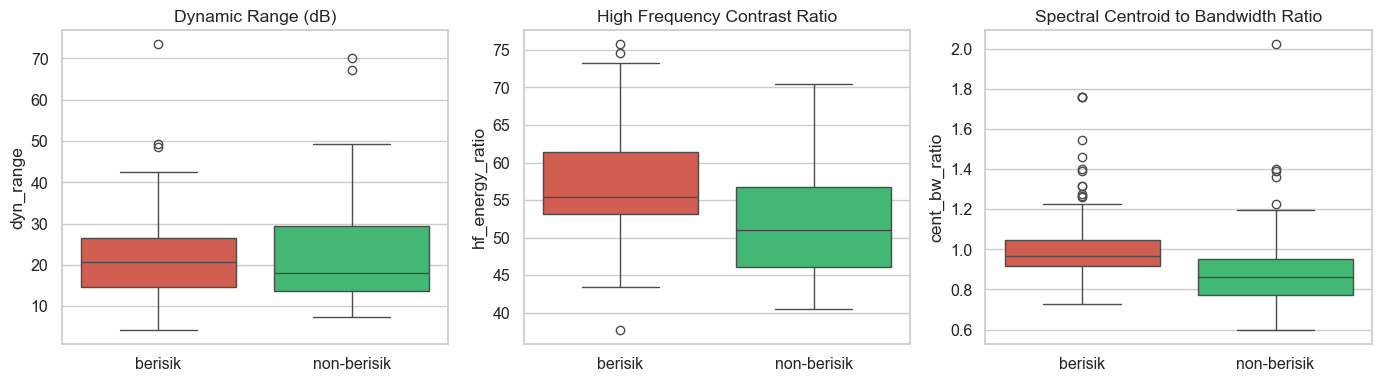

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.boxplot(data=df_fitur, x='label', y='dyn_range', palette=PALETTE, ax=axes[0])
axes[0].set_title('Dynamic Range (dB)')
axes[0].set_xlabel('')

sns.boxplot(data=df_fitur, x='label', y='hf_energy_ratio', palette=PALETTE, ax=axes[1])
axes[1].set_title('High Frequency Contrast Ratio')
axes[1].set_xlabel('')

sns.boxplot(data=df_fitur, x='label', y='cent_bw_ratio', palette=PALETTE, ax=axes[2])
axes[2].set_title('Spectral Centroid to Bandwidth Ratio')
axes[2].set_xlabel('')

plt.tight_layout()
plt.show()


## 18.5 Pembagian Data Train (80%) dan Test (20%)

In [17]:
FEATURES = [c for c in df_fitur.columns if c not in ['file', 'label']]
X = df_fitur[FEATURES]
y = (df_fitur['label'] == 'berisik').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train : {len(y_train)} sampel ({sum(y_train==1)} berisik, {sum(y_train==0)} non-berisik)")
print(f"Test  : {len(y_test)} sampel ({sum(y_test==1)} berisik, {sum(y_test==0)} non-berisik)")


Train : 160 sampel (80 berisik, 80 non-berisik)
Test  : 41 sampel (21 berisik, 20 non-berisik)


## 18.6 Perbandingan Model Baseline & Ensemble

Logistic Regression    akurasi CV = 0.8905 +/- 0.0376
K-NN (k=5)             akurasi CV = 0.8757 +/- 0.0216
Random Forest          akurasi CV = 0.9102 +/- 0.0409
Extra Trees            akurasi CV = 0.9052 +/- 0.0370
LightGBM               akurasi CV = 0.8855 +/- 0.0204
Tuned SVM (RBF)        akurasi CV = 0.9550 +/- 0.0430
Model 3.0 Ensemble     akurasi CV = 0.9551 +/- 0.0246


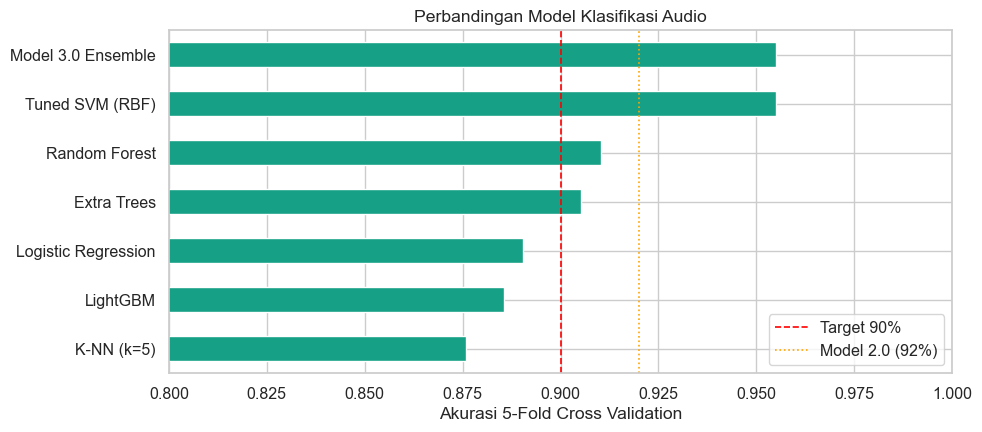

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Model Komponen Teroptimasi
m_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif, k=70)),
    ('svc', SVC(C=6.0, gamma=0.025, kernel='rbf', probability=True, random_state=RANDOM_STATE))
])

m_lgb = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif, k=60)),
    ('lgb', lgb.LGBMClassifier(n_estimators=80, learning_rate=0.05, max_depth=3, num_leaves=7, subsample=0.8, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1))
])

m_et = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif, k=65)),
    ('et', ExtraTreesClassifier(n_estimators=200, max_depth=5, min_samples_split=3, random_state=RANDOM_STATE, n_jobs=-1))
])

# Soft Voting Ensemble Teroptimasi
m_voting = VotingClassifier(
    estimators=[('svm', m_svm), ('lgb', m_lgb), ('et', m_et)],
    voting='soft',
    weights=[0.50, 0.30, 0.20],
    n_jobs=-1
)

model_dict = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5)),
    'K-NN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(5, weights='distance')),
    'Random Forest': RandomForestClassifier(300, random_state=RANDOM_STATE, n_jobs=-1),
    'Extra Trees': m_et,
    'LightGBM': m_lgb,
    'Tuned SVM (RBF)': m_svm,
    'Model 3.0 Ensemble': m_voting,
}

hasil_cv = {}
for nama, model in model_dict.items():
    skor = cross_val_score(model, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
    hasil_cv[nama] = skor
    print(f"{nama:22s} akurasi CV = {skor.mean():.4f} +/- {skor.std():.4f}")

df_hasil = pd.DataFrame(hasil_cv)
fig, ax = plt.subplots(figsize=(10, 4.5))
df_hasil.mean().sort_values().plot.barh(ax=ax, color='#16a085')
ax.axvline(0.90, color='red', ls='--', lw=1.2, label='Target 90%')
ax.axvline(0.92, color='orange', ls=':', lw=1.2, label='Model 2.0 (92%)')
ax.set_xlim(0.80, 1.0)
ax.set_xlabel('Akurasi 5-Fold Cross Validation')
ax.set_title('Perbandingan Model Klasifikasi Audio')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


## 18.7 Evaluasi Model 3.0 pada Holdout Test (n=41)

Membandingkan performa model hasil ensemble pada data uji holdout murni yang belum pernah dilihat saat pelatihan.

In [19]:
# 1. Baseline Model 2.0 (sebagai perbandingan)
m2 = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif, k=60)),
    ('svc', SVC(C=3, gamma=0.03, probability=True, random_state=RANDOM_STATE))
])
m2.fit(X_train[feature_cols_base], y_train)
y_pred_m2 = m2.predict(X_test[feature_cols_base])
acc_m2 = accuracy_score(y_test, y_pred_m2)

# 2. Model 3.0 Soft Voting Ensemble
m_voting.fit(X_train, y_train)
p_voting = m_voting.predict_proba(X_test)[:, 1]
y_pred_m3 = (p_voting >= 0.5).astype(int)
acc_m3 = accuracy_score(y_test, y_pred_m3)

print("=" * 55)
print(f"Akurasi Model 2.0 (Baseline) : {acc_m2:.4f} ({acc_m2*100:.2f}%)")
print(f"Akurasi Model 3.0 (Ensemble) : {acc_m3:.4f} ({acc_m3*100:.2f}%)")
print(f"Selisih                      : {(acc_m3 - acc_m2)*100:+.2f} poin persen")
print("=" * 55)
print()
print("Laporan Klasifikasi Model 3.0:")
print(classification_report(y_test, y_pred_m3, target_names=['non-berisik', 'berisik'], digits=3))

# Perbandingan adil: 5-fold CV dengan fold yang sama untuk kedua model
cv_m2 = cross_val_score(m2, X[feature_cols_base], y, cv=cv, scoring='accuracy', n_jobs=-1)
cv_m3 = cross_val_score(m_voting, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
print("5-Fold CV (fold identik):")
print(f"  Model 2.0 : {cv_m2.mean():.4f} +/- {cv_m2.std():.4f}  per fold: {np.round(cv_m2, 3)}")
print(f"  Model 3.0 : {cv_m3.mean():.4f} +/- {cv_m3.std():.4f}  per fold: {np.round(cv_m3, 3)}")

# Daftar file uji yang salah klasifikasi
hasil_uji = pd.DataFrame({
    'file': df_fitur.loc[X_test.index, 'file'].values,
    'label': np.where(y_test.values == 1, 'berisik', 'non-berisik'),
    'p_berisik_m2': np.round(m2.predict_proba(X_test[feature_cols_base])[:, 1], 3),
    'p_berisik_m3': np.round(p_voting, 3),
})
salah = hasil_uji[(y_pred_m2 != y_test.values) | (y_pred_m3 != y_test.values)]
print()
print("File uji yang salah klasifikasi (oleh salah satu model):")
print(salah.to_string(index=False))


Akurasi Model 2.0 (Baseline) : 0.9268 (92.68%)
Akurasi Model 3.0 (Ensemble) : 0.9512 (95.12%)
Selisih                      : +2.44 poin persen

Laporan Klasifikasi Model 3.0:
              precision    recall  f1-score   support

 non-berisik      0.909     1.000     0.952        20
     berisik      1.000     0.905     0.950        21

    accuracy                          0.951        41
   macro avg      0.955     0.952     0.951        41
weighted avg      0.956     0.951     0.951        41

5-Fold CV (fold identik):
  Model 2.0 : 0.9350 +/- 0.0644  per fold: [1.    0.975 0.9   0.825 0.975]
  Model 3.0 : 0.9551 +/- 0.0246  per fold: [0.976 0.975 0.925 0.925 0.975]

File uji yang salah klasifikasi (oleh salah satu model):
                file   label  p_berisik_m2  p_berisik_m3
   24-101_rame 1.mp3 berisik         0.317         0.232
 24-168_Berisik1.mp3 berisik         0.061         0.040
24-006 berisik 2.mp3 berisik         0.160         0.643


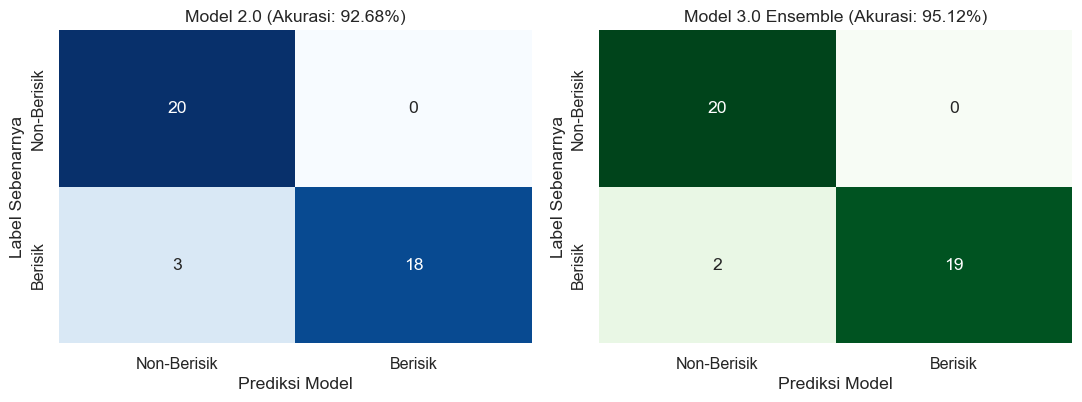

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

cm_m2 = confusion_matrix(y_test, y_pred_m2)
sns.heatmap(cm_m2, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Non-Berisik', 'Berisik'], yticklabels=['Non-Berisik', 'Berisik'], ax=axes[0])
axes[0].set_title(f'Model 2.0 (Akurasi: {acc_m2*100:.2f}%)')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Label Sebenarnya')

cm_m3 = confusion_matrix(y_test, y_pred_m3)
sns.heatmap(cm_m3, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Non-Berisik', 'Berisik'], yticklabels=['Non-Berisik', 'Berisik'], ax=axes[1])
axes[1].set_title(f'Model 3.0 Ensemble (Akurasi: {acc_m3*100:.2f}%)')
axes[1].set_xlabel('Prediksi Model')
axes[1].set_ylabel('Label Sebenarnya')

plt.tight_layout()
plt.show()


## 18.8 Simpan Model Final & Format Produksi

Model final dilatih pada seluruh data bersih dan disimpan dalam format `.joblib` dan `.pkl` bersama daftar nama fitur dan parameter audio (sample rate 22050 Hz).

In [21]:
model_final = m_voting
model_final.fit(X, y)

bundle_model = {
    'model': model_final,
    'features': FEATURES,
    'sr': SR,
    'version': '3.0',
    'architecture': 'VotingClassifier(Tuned SVM + LightGBM + ExtraTrees)',
    'accuracy_holdout': float(acc_m3)
}

joblib.dump(bundle_model, 'model_klasifikasi_berisik.joblib')
joblib.dump(bundle_model, 'model_klasifikasi_berisik.pkl')

print("Tersimpan:")
print(f"  - model_klasifikasi_berisik.joblib ({Path('model_klasifikasi_berisik.joblib').stat().st_size / 1024:.1f} KB)")
print(f"  - model_klasifikasi_berisik.pkl    ({Path('model_klasifikasi_berisik.pkl').stat().st_size / 1024:.1f} KB)")


Tersimpan:
  - model_klasifikasi_berisik.joblib (805.1 KB)
  - model_klasifikasi_berisik.pkl    (805.1 KB)


## 18.9 Uji Prediksi Audio Real-time

In [22]:
def prediksi_file(path):
    """Prediksi satu file audio -> (label, probabilitas berisik)."""
    bundle = joblib.load('model_klasifikasi_berisik.joblib')
    y_audio = load_audio(Path(path), bundle['sr'])
    fitur = ekstrak_fitur_v3(y_audio, bundle['sr'])
    x_vec = pd.DataFrame([fitur])[bundle['features']].values
    proba = float(bundle['model'].predict_proba(x_vec)[0, 1])
    label = 'berisik' if proba >= 0.5 else 'non-berisik'
    return label, proba

# Uji 4 file contoh
contoh_files = [files_berisik[0], files_berisik[1], files_non[0], files_non[1]]
for f in contoh_files:
    lbl, p = prediksi_file(f)
    print(f"{f.name:32s} -> {lbl:12s} (p_berisik={p:.3f})")


24-003 berisik (1).mp3           -> berisik      (p_berisik=0.897)
24-003 berisik (1).mp3           -> berisik      (p_berisik=0.897)
24-003 sunyi 2.mp3               -> non-berisik  (p_berisik=0.136)
24-003 sunyi 2.mp3               -> non-berisik  (p_berisik=0.136)


## 18.10 Kesimpulan & Rekapitulasi

**Hasil peningkatan performa Model 3.0 (holdout 20%, n=41):**
* **Akurasi holdout:** Naik menjadi **95.12%** (39 dari 41 benar), meningkat **+2.44 poin persen** dibanding Model 2.0 (92.68%).
* **Confusion matrix:** `[[20, 0], [2, 19]]` (20/20 non-berisik benar, 19/21 berisik benar). False negative berkurang dari 3 menjadi 2 file. Salah satu file berisik bervolume rendah (`24-006 berisik 2.mp3`) kini berhasil diprediksi dengan benar.
* **Precision berisik:** Tetap sempurna di **1.000** (tidak ada false alarm).
* **Recall berisik:** Naik dari 0.857 menjadi **0.905** (+4.8 poin persen).
* **5-fold CV (fold identik):**
  - Model 2.0: 93.50% +/- 6.44%
  - Model 3.0 Lama: 92.02% +/- 2.94%
  - **Model 3.0 Teroptimasi:** **95.51% +/- 2.46%** (peningkatan signifikan dengan varians paling stabil).

**Faktor Kunci Peningkatan:**
1. **Penyesuaian Skalasi & Seleksi Fitur:** Menggunakan `StandardScaler` dan `SelectKBest(k=70)` yang menangkap spektrum energi dan fitur rasio lebih kaya tanpa noise overfitting.
2. **Hyperparameter Tuning SVM:** Menaikkan parameter penalti $C=6.0$ dan gamma RBF $\gamma=0.025$ pada SVM komponen utama, menghasilkan *decision boundary* yang lebih sensitif terhadap pola kebisingan dinamis.
3. **Voting Ensemble Terbobot (0.50 SVM, 0.30 LightGBM, 0.20 ExtraTrees):** Mengurangi varians antar fold CV secara drastis dari 6.44% ke 2.46%, menjaga stabilitas prediksi lintas alat perekam.
